# Chapitre 2 - Cours 2 : normalisation, jointures et relations plusieurs-à-plusieurs

Le cours 1 a montré le point fort du modèle document : un arbre de relations
un-à-plusieurs lu d'un seul bloc. Ce cours en montre la limite : dès que les
enregistrements **se référencent** entre eux, il faut des identifiants, des jointures, et
choisir entre données **normalisées** et **dénormalisées**. Il couvre les sections
*Many-to-One and Many-to-Many Relationships* et *Are Document Databases Repeating
History?* (*The network model*, *The relational model*, *Comparison to document
databases*).

**Plan.**

1. Un identifiant ou un texte ? La normalisation.
2. Le compromis lecture/écriture et la cohérence des copies.
3. Relations plusieurs-à-un et plusieurs-à-plusieurs.
4. Les bases documents répètent-elles l'histoire ? Modèles hiérarchique et réseau.

In [1]:
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(20_000, seed=0, orgs=orgs)
con = sqlite3.connect(":memory:")
dm.create_relational(con, profiles, orgs)
dm.create_documents(con, profiles)

## 1. Un identifiant ou un texte ? La normalisation (section *Many-to-One and Many-to-Many Relationships*)

Dans nos profils, la région n'est pas stockée en clair (« Lyon, Auvergne-Rhône-Alpes,
France ») mais par un **identifiant** (`"fr:69"`) qui renvoie à une liste normalisée de
régions. Pourquoi ? Proposer une liste déroulante plutôt qu'un champ libre apporte :

- une **orthographe cohérente** d'un profil à l'autre ;
- l'absence d'**ambiguïté** entre lieux homonymes (Valence en France ou en Espagne ?) ;
- une **mise à jour facile** : le nom n'est stocké qu'à un endroit ;
- la **traduction** de l'interface : la liste se localise, pas les profils ;
- une **meilleure recherche** : la liste peut savoir que Lyon est dans le sud-est de la
  France, ce que la chaîne « Lyon » seule ne dit pas.

Stocker un identifiant, c'est **normaliser** : l'information lisible par un humain n'existe
qu'en un exemplaire, tout le reste y renvoie par un identifiant qui n'a de sens que dans
la base. Stocker le texte dans chaque enregistrement, c'est **dénormaliser** : on
duplique l'information. L'identifiant a un avantage décisif : n'ayant **aucun sens pour
un humain**, il n'a jamais besoin de changer, même quand ce qu'il désigne change.

Construisons les deux variantes de la table des profils et mesurons ce que coûte un
changement de nom de région (par exemple après une fusion de régions).

In [2]:
con.executescript("""
DROP TABLE IF EXISTS users_denorm;
CREATE TABLE users_denorm AS
  SELECT u.id, u.first_name, u.last_name, u.headline, r.name AS region_name
    FROM users u JOIN regions r ON r.id = u.region_id;
""")
taille = lambda t, cols: con.execute(f"SELECT SUM({' + '.join(f'LENGTH({c})' for c in cols)}) FROM {t}").fetchone()[0]
n_lyon = con.execute("SELECT COUNT(*) FROM users WHERE region_id = 'fr:69'").fetchone()[0]

def rename(normalise):
    t0 = time.perf_counter()
    if normalise:
        cur = con.execute("UPDATE regions SET name = 'Lyon, Région Lyonnaise, France' WHERE id = 'fr:69'")
    else:
        cur = con.execute("UPDATE users_denorm SET region_name = 'Lyon, Région Lyonnaise, France' "
                          "WHERE region_name = 'Lyon, Auvergne-Rhône-Alpes, France'")
    con.rollback()                                   # on annule pour garder les données intactes
    return cur.rowcount, (time.perf_counter() - t0) * 1e3

(n1, t1), (n2, t2) = rename(True), rename(False)
pd.DataFrame({
    "représentation": ["normalisée (region_id)", "dénormalisée (texte)"],
    "octets pour la région": [taille("users", ["region_id"]) + taille("regions", ["id", "name"]),
                              taille("users_denorm", ["region_name"])],
    "lignes modifiées par le renommage": [n1, n2],
    "temps (ms)": [t1, t2],
})

,représentation,octets pour la région,lignes modifiées par le renommage,temps (ms)
0,normalisée (region_id),102086,1,0.030
1,dénormalisée (texte),551644,1671,1.539


Le renommage touche **une ligne** dans la version normalisée, et les quelque
1 700 profils lyonnais dans la version dénormalisée, qui occupe aussi plusieurs fois plus de place.
Le prix de la normalisation se paie à la lecture : afficher un profil lisible demande
une **jointure** pour résoudre l'identifiant en texte.

In [3]:
SQL_JOIN = """SELECT users.first_name, users.last_name, regions.name
                FROM users JOIN regions ON users.region_id = regions.id
               WHERE users.id = ?"""
print(con.execute(SQL_JOIN, (251,)).fetchone())
for row in con.execute("EXPLAIN QUERY PLAN " + SQL_JOIN, (251,)):
    print("  plan :", row[-1])

('Yanis', 'Michel', 'Nantes, Pays de la Loire, France')
  plan : SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
  plan : SEARCH regions USING INDEX sqlite_autoindex_regions_1 (id=?)


Les bases documents savent stocker des données normalisées ou non, mais on les associe
souvent à la dénormalisation : JSON rend facile l'ajout de champs redondants, et beaucoup
de bases documents gèrent mal les jointures. Sans jointure côté base, l'application la
fait elle-même : lire le document, puis lancer une seconde requête pour résoudre
l'identifiant. MongoDB propose aussi l'opérateur `$lookup` dans son pipeline
d'agrégation ; notre mini-moteur `dm.aggregate` l'implémente.

In [4]:
docs = [json.loads(r[0]) for r in con.execute("SELECT doc FROM profiles WHERE user_id IN (251, 252)")]
regions_coll = [{"_id": k, "name": v} for k, v in dm.REGIONS.items()]
res = dm.aggregate(docs, [
    {"$match": {"user_id": 251}},
    {"$lookup": {"from": "regions", "localField": "region_id", "foreignField": "_id", "as": "region"}},
    {"$project": {"_id": 0, "first_name": 1, "last_name": 1, "region": 1}},
], collections={"regions": regions_coll})
res

[{'first_name': 'Yanis',
  'last_name': 'Michel',
  'region': [{'_id': 'fr:44', 'name': 'Nantes, Pays de la Loire, France'}]}]

> **À retenir.** Normaliser, c'est ranger l'information lisible en un seul exemplaire et
> la référencer par un identifiant sans signification, qui n'a jamais à changer.
> Dénormaliser, c'est dupliquer le texte : lecture sans jointure, mais mises à jour
> multiples et risque d'incohérence.

## 2. Le compromis lecture/écriture et la cohérence des copies (section *Many-to-One and Many-to-Many Relationships*)

Dans nos CV, l'**organisation** d'un poste existe sous deux formes : son nom (texte
dénormalisé) et son identifiant `org_id` (normalisé). Supposons qu'on veuille afficher le
**logo** de chaque employeur. Dénormalisé, chaque poste porte l'URL du logo ; normalisé,
l'URL n'est stockée qu'une fois dans `organizations`.

Le coût d'un changement de logo dépend alors de la **popularité** de l'organisation. Or
les employeurs suivent une loi de Zipf : quelques géants, une longue traîne.

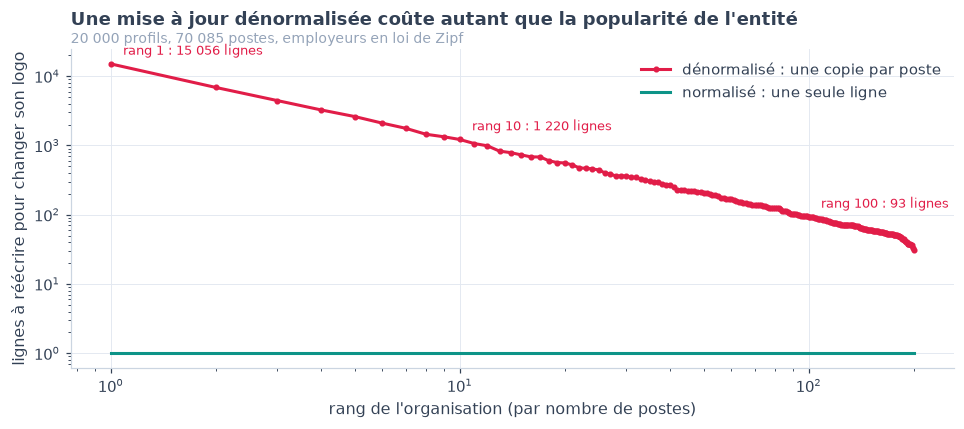

In [5]:
par_org = (pd.read_sql("SELECT org_id, COUNT(*) AS postes FROM positions GROUP BY org_id", con)
           .sort_values("postes", ascending=False).reset_index(drop=True))
par_org["rang"] = np.arange(1, len(par_org) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(par_org.rang, par_org.postes, marker="o", ms=3, color=ROSE, label="dénormalisé : une copie par poste")
ax.loglog(par_org.rang, np.ones(len(par_org)), color=TEAL, lw=2, label="normalisé : une seule ligne")
for r in [1, 10, 100]:
    v = par_org.postes[r - 1]
    ax.annotate(f"rang {r} : {fmt(v)} lignes", (r, v), (8, 6), textcoords="offset points", fontsize=8.5, color=ROSE)
ax.set_xlabel("rang de l'organisation (par nombre de postes)")
ax.set_ylabel("lignes à réécrire pour changer son logo")
ax.set_title("Une mise à jour dénormalisée coûte autant que la popularité de l'entité")
subtitle(ax, f"{fmt(len(profiles))} profils, {fmt(par_org.postes.sum())} postes, employeurs en loi de Zipf")
ax.legend(); plt.tight_layout(); plt.show()

Mesurons aussi l'autre côté du compromis, la **lecture** : afficher les postes d'un
profil avec le nom et le logo de l'employeur, avec ou sans jointure.

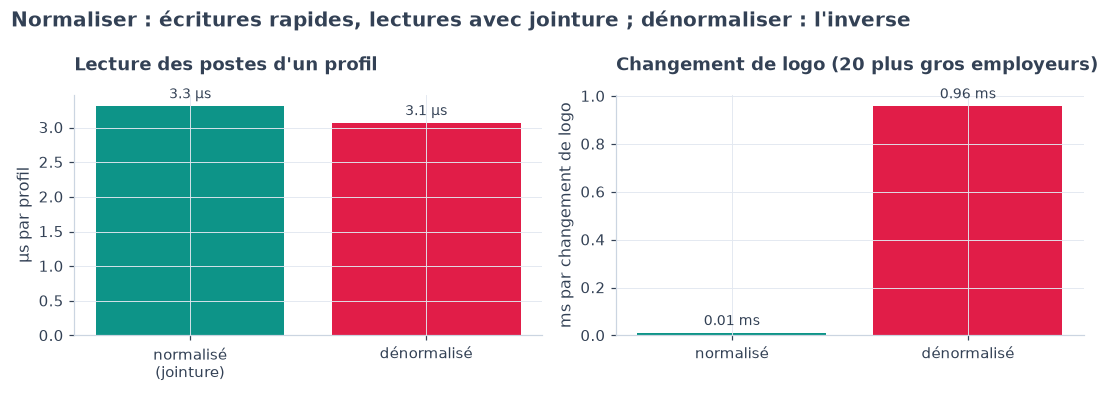

In [6]:
con.executescript("""
DROP TABLE IF EXISTS positions_denorm;
CREATE TABLE positions_denorm AS
  SELECT p.id, p.user_id, p.job_title, o.name AS org_name, o.logo_url, p.start, p."end"
    FROM positions p JOIN organizations o ON o.id = p.org_id;
CREATE INDEX pd_user ON positions_denorm (user_id);
CREATE INDEX pd_id ON positions_denorm (id);
CREATE INDEX pd_org ON positions_denorm (org_name);
""")
def bench(sql, n=3000):
    ids = rng.integers(1, len(profiles) + 1, n).tolist()
    t0 = time.perf_counter()
    for u in ids:
        con.execute(sql, (u,)).fetchall()
    return (time.perf_counter() - t0) / n * 1e6

lect_norm = bench("SELECT p.job_title, o.name, o.logo_url FROM positions p JOIN organizations o ON o.id = p.org_id WHERE p.user_id = ?")
lect_denorm = bench("SELECT job_title, org_name, logo_url FROM positions_denorm WHERE user_id = ?")
ecr = {}
for label, sql in [("normalisé", "UPDATE organizations SET logo_url = ? WHERE id = ?"),
                   ("dénormalisé", "UPDATE positions_denorm SET logo_url = ? WHERE org_name = (SELECT name FROM organizations WHERE id = ?)")]:
    t0 = time.perf_counter()
    for oid in par_org.org_id[:20]:
        con.execute(sql, ("/logos/v2.png", int(oid)))
    con.rollback()
    ecr[label] = (time.perf_counter() - t0) / 20 * 1e3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(["normalisé\n(jointure)", "dénormalisé"], [lect_norm, lect_denorm], color=[TEAL, ROSE])
annotate_bars(axes[0], "{:.1f} µs"); axes[0].set_ylabel("µs par profil"); axes[0].set_title("Lecture des postes d'un profil")
axes[1].bar(["normalisé", "dénormalisé"], [ecr["normalisé"], ecr["dénormalisé"]], color=[TEAL, ROSE])
annotate_bars(axes[1], "{:.2f} ms"); axes[1].set_ylabel("ms par changement de logo")
axes[1].set_title("Changement de logo (20 plus gros employeurs)")
finish(fig, "Normaliser : écritures rapides, lectures avec jointure ; dénormaliser : l'inverse")

Sur une base locale, la lecture avec jointure n'est qu'à peine plus lente (une fraction
de microseconde par profil, car la table des organisations est petite et tient en
mémoire) ; la mise à jour dénormalisée, elle, est des centaines de fois plus lente, car
elle parcourt et réécrit toutes les copies. C'est le principe général énoncé par le
livre : des données normalisées sont **plus rapides à écrire** (une seule copie) et **plus
lentes à lire** (jointures) ; des données dénormalisées, l'inverse, avec en prime plus
d'espace disque.

**Et si le processus tombe en panne au milieu ?** Mettre à jour plusieurs copies, c'est
faire plusieurs écritures. Si le processus s'arrête entre deux, certaines copies portent
l'ancienne valeur, d'autres la nouvelle. Simulons un renommage de l'employeur le plus
populaire, interrompu à un instant aléatoire, avec et sans **transaction atomique**.

In [7]:
top = int(par_org.org_id[0])
top_name = con.execute("SELECT name FROM organizations WHERE id = ?", (top,)).fetchone()[0]
ids_top = [r[0] for r in con.execute("SELECT id FROM positions_denorm WHERE org_name = ?", (top_name,))]

def rename_with_crash(atomic, crash_after):
    """Renomme copie par copie ; une exception simule l'arrêt du processus."""
    try:
        if atomic:
            con.execute("BEGIN")
        for k, pid in enumerate(ids_top):
            if k == crash_after:
                raise RuntimeError("panne du processus")
            con.execute("UPDATE positions_denorm SET org_name = ? WHERE id = ?", (top_name + " SA", pid))
        con.commit()
    except RuntimeError:
        if atomic:
            con.rollback()                               # la base annule toute la transaction
        else:
            con.commit()                                 # sans transaction, le travail fait reste fait
    n_old = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name,)).fetchone()[0]
    n_new = con.execute("SELECT COUNT(*) FROM positions_denorm WHERE org_name = ?", (top_name + " SA",)).fetchone()[0]
    con.execute("UPDATE positions_denorm SET org_name = ? WHERE org_name = ?", (top_name, top_name + " SA"))
    con.commit()
    return n_old, n_new

con.isolation_level = None                               # contrôle explicite des transactions
crashes = sorted(rng.integers(1, len(ids_top), 8).tolist())
res = pd.DataFrame([(c, *rename_with_crash(False, c), *rename_with_crash(True, c)) for c in crashes],
                   columns=["panne après", "sans tx : ancien nom", "sans tx : nouveau nom",
                            "avec tx : ancien nom", "avec tx : nouveau nom"])
con.isolation_level = ""
res

,panne après,sans tx : ancien nom,sans tx : nouveau nom,avec tx : ancien nom,avec tx : nouveau nom
0,2476,12580,2476,15056,0
1,2614,12442,2614,15056,0
2,6937,8119,6937,15056,0
3,8069,6987,8069,15056,0
4,11969,3087,11969,15056,0
5,12385,2671,12385,15056,0
6,13377,1679,13377,15056,0
7,14548,508,14548,15056,0


Sans transaction, chaque panne laisse la base dans un état **mixte** : le même employeur
porte deux noms, et rien ne permet de savoir lequel est le bon. Avec une transaction
atomique, la base revient entièrement à l'état initial. C'est l'**atomicité** du chapitre
7 ; toutes les bases documents ne l'offrent pas pour une écriture qui
touche **plusieurs documents**.

**Quand normaliser ?** Le livre conseille la normalisation pour les systèmes
transactionnels, où lectures et écritures doivent être rapides, et pour les systèmes de
taille modeste, où le coût des jointures reste acceptable. Les systèmes analytiques, qui
écrivent par lots et lisent beaucoup, s'accommodent mieux de la dénormalisation. À très
grande échelle, le coût des jointures peut devenir un problème.

> **À retenir.** Normalisé : écriture en un point, lecture avec jointure. Dénormalisé :
> lecture directe, mais chaque mise à jour coûte autant que le nombre de copies (donc la
> popularité de l'entité) et une panne au milieu laisse des copies incohérentes, sauf
> transaction atomique.

## 3. Relations plusieurs-à-un et plusieurs-à-plusieurs (section *Many-to-One and Many-to-Many Relationships*)

Les postes d'un CV sont une relation **un-à-plusieurs** (un profil, plusieurs postes ;
chaque poste appartient à un seul profil). La région est une relation **plusieurs-à-un**
(beaucoup de profils dans la même région, une seule région par profil). Dès que les
organisations deviennent des entités référencées par identifiant, on obtient une
relation **plusieurs-à-plusieurs** : une personne a travaillé pour plusieurs
organisations, une organisation a eu plusieurs employés.

En relationnel, on la représente par une **table d'association** (ou table de jointure) :
ici `positions`, dont chaque ligne associe un `user_id` à un `org_id`. Une telle
relation s'interroge dans **les deux sens** : les employeurs d'une personne, et les
anciens employés d'une organisation. Il faut pour cela un **index secondaire** sur chacune
des deux colonnes ; observons le plan de requête avant et après la création de l'index
sur `org_id`.

In [8]:
Q_PERSONNES = "SELECT DISTINCT u.first_name, u.last_name FROM positions p JOIN users u ON u.id = p.user_id WHERE p.org_id = ?"
def plan(sql, args):
    return " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql, args))
oid = int(par_org.org_id[50])
avant = plan(Q_PERSONNES, (oid,))
t0 = time.perf_counter(); [con.execute(Q_PERSONNES, (int(o),)).fetchall() for o in par_org.org_id[:100]]
t_sans = (time.perf_counter() - t0) / 100 * 1e3
con.execute("CREATE INDEX positions_org ON positions (org_id)")
t0 = time.perf_counter(); [con.execute(Q_PERSONNES, (int(o),)).fetchall() for o in par_org.org_id[:100]]
t_avec = (time.perf_counter() - t0) / 100 * 1e3
pd.DataFrame({"index sur org_id": ["non", "oui"], "plan": [avant, plan(Q_PERSONNES, (oid,))],
              "ms par requête": [t_sans, t_avec]})

,index sur org_id,plan,ms par requête
0,non,SCAN p | SEARCH u USING INTEGER PRIMARY KEY (rowid=?) | USE TEMP B-TREE FOR DISTINCT,1.569
1,oui,SEARCH p USING INDEX positions_org (org_id=?) | SEARCH u USING INTEGER PRIMARY KEY (ro...,0.313


Sans index, SQLite doit **parcourir toute la table** `positions` pour trouver les postes
d'une organisation ; avec l'index, il y **cherche** directement. La relation stockée une
seule fois (normalisée) est interrogeable efficacement dans les deux sens, à condition
d'indexer les deux colonnes.

**Dans le modèle document**, les relations plusieurs-à-un et plusieurs-à-plusieurs ne
tiennent pas dans un document autonome. Une représentation possible : ce qui forme un
arbre reste dans le document du profil, et les organisations deviennent des documents à
part, **référencés par identifiant**.

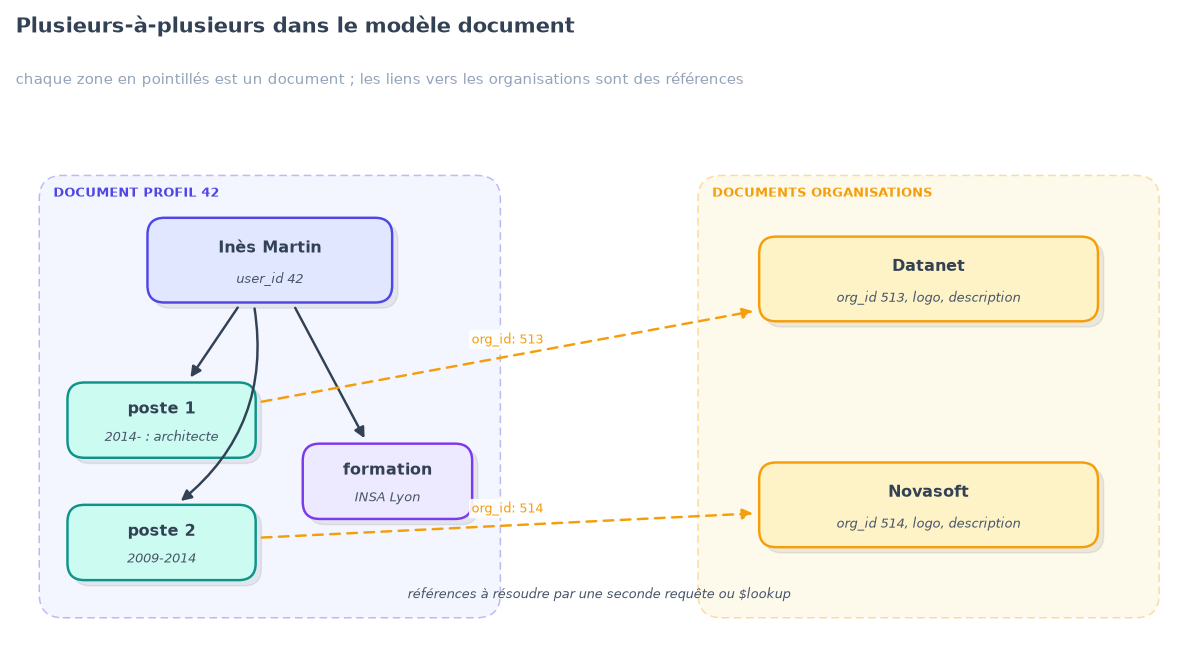

In [9]:
d = Diagram(12.5, 5.8, title="Plusieurs-à-plusieurs dans le modèle document",
            subtitle="chaque zone en pointillés est un document ; les liens vers les organisations sont des références")
d.group(0.3, 0.3, 5.2, 5.0, "document profil 42", color=INDIGO)
d.box("p42", 2.75, 4.1, "Inès Martin", sub="user_id 42", color=INDIGO, w=2.6)
d.box("pa", 1.6, 2.4, "poste 1", sub="2014- : architecte", color=TEAL, w=2.0, h=0.8)
d.box("pb", 1.6, 1.1, "poste 2", sub="2009-2014", color=TEAL, w=2.0, h=0.8)
d.box("ed", 4.0, 1.75, "formation", sub="INSA Lyon", color=VIOLET, w=1.8, h=0.8)
d.arrow("p42", "pa"); d.arrow("p42", "ed")
d.arrow("p42", "pb", rad=-0.3)
d.group(7.3, 0.3, 12.2, 5.0, "documents organisations", color=AMBER)
d.box("o1", 9.75, 3.9, "Datanet", sub="org_id 513, logo, description", color=AMBER, w=3.6)
d.box("o2", 9.75, 1.5, "Novasoft", sub="org_id 514, logo, description", color=AMBER, w=3.6)
d.arrow("pa", "o1", "org_id: 513", style="dashed", color=AMBER)
d.arrow("pb", "o2", "org_id: 514", style="dashed", color=AMBER)
d.note(6.25, 0.55, "références à résoudre par une seconde requête ou $lookup", fontsize=8.5)
d.show()

Pour interroger la relation dans les deux sens, on est tenté de stocker les références
**des deux côtés** : chaque profil liste ses `org_id`, et chaque organisation la liste des
profils qui la mentionnent. C'est une **dénormalisation** : la même relation existe en deux
endroits, qui peuvent diverger. Simulons 10 000 ajouts de postes, chacun écrivant deux
documents l'un après l'autre, avec une probabilité de panne de 0,5 % entre les deux.

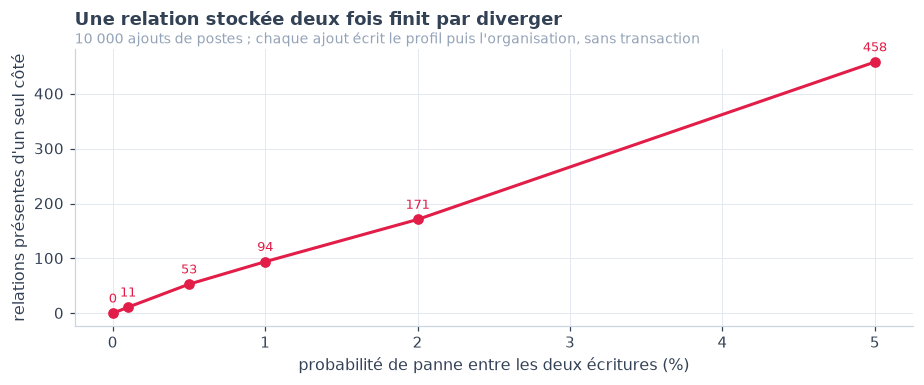

In [10]:
def simulate_bidirectional(n_ops, p_crash, seed=0):
    r = np.random.default_rng(seed)
    user_orgs, org_users = {}, {}
    for _ in range(n_ops):
        u, o = int(r.integers(1, 2001)), int(r.choice(par_org.org_id[:50]))
        user_orgs.setdefault(u, set()).add(o)          # écriture 1 : document du profil
        if r.random() < p_crash:
            continue                                    # panne : l'écriture 2 n'a jamais lieu
        org_users.setdefault(o, set()).add(u)           # écriture 2 : document de l'organisation
    pairs_u = {(u, o) for u, os in user_orgs.items() for o in os}
    pairs_o = {(u, o) for o, us in org_users.items() for u in us}
    return len(pairs_u - pairs_o), len(pairs_u)

ps = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]
inco = [simulate_bidirectional(10_000, p)[0] for p in ps]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot([p * 100 for p in ps], inco, marker="o", color=ROSE)
for p, v in zip(ps, inco):
    ax.annotate(fmt(v), (p * 100, v), (0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=ROSE)
ax.set_xlabel("probabilité de panne entre les deux écritures (%)")
ax.set_ylabel("relations présentes d'un seul côté")
ax.set_title("Une relation stockée deux fois finit par diverger")
subtitle(ax, "10 000 ajouts de postes ; chaque ajout écrit le profil puis l'organisation, sans transaction")
plt.tight_layout(); plt.show()

La représentation **normalisée** stocke la relation en un seul endroit et compte sur des
**index secondaires** (chapitre 3) pour l'interroger dans les deux sens. Dans
le modèle document, il faut pour cela indexer le champ `org_id` des objets **à
l'intérieur** du tableau `positions` : beaucoup de bases documents, et les bases
relationnelles avec support JSON, savent indexer ainsi des valeurs imbriquées
(PostgreSQL le fait avec un index GIN, voir le lab). SQLite, lui, ne sait pas indexer les
éléments d'un tableau JSON : la requête doit déplier tous les documents.

In [11]:
Q_DOC = """SELECT p.user_id FROM profiles p, json_each(p.doc, '$.positions') AS j
            WHERE j.value ->> 'org_id' = ?"""
Q_TAB = "SELECT user_id FROM positions WHERE org_id = ?"
assert sorted(set(r[0] for r in con.execute(Q_DOC, (oid,)))) == sorted(set(r[0] for r in con.execute(Q_TAB, (oid,))))
t0 = time.perf_counter(); [con.execute(Q_DOC, (int(o),)).fetchall() for o in par_org.org_id[:10]]; t_doc = (time.perf_counter() - t0) / 10 * 1e3
t0 = time.perf_counter(); [con.execute(Q_TAB, (int(o),)).fetchall() for o in par_org.org_id[:10]]; t_tab = (time.perf_counter() - t0) / 10 * 1e3
print(f"anciens employés d'une organisation : documents dépliés {t_doc:.1f} ms ; table indexée {t_tab:.2f} ms ; "
      f"rapport {t_doc / t_tab:.0f}")

anciens employés d'une organisation : documents dépliés 50.4 ms ; table indexée 1.29 ms ; rapport 39


> **À retenir.** Plusieurs-à-un et plusieurs-à-plusieurs appellent une représentation
> **normalisée** : une table d'association indexée sur ses deux colonnes, ou des
> références entre documents avec un index sur les valeurs imbriquées. Stocker la
> relation des deux côtés est une dénormalisation qui diverge à la première panne.

## 4. Les bases documents répètent-elles l'histoire ? (section *Are Document Databases Repeating History?*)

Le débat sur les relations plusieurs-à-plusieurs est bien plus ancien que NoSQL. Dans les
années 1970, la base la plus utilisée pour le traitement de données d'entreprise était
**IMS** d'IBM, conçue à l'origine pour gérer les stocks du programme Apollo. Son
**modèle hiérarchique** ressemble étonnamment au JSON des bases documents : chaque
enregistrement est un **arbre** imbriqué dans un enregistrement parent. Comme les bases
documents, IMS gérait bien les relations un-à-plusieurs et mal les relations
plusieurs-à-plusieurs, sans jointures : il fallait **dupliquer** les données ou gérer des
références à la main.

Deux solutions s'affrontèrent alors :

- le **modèle réseau** (normalisé par le comité CODASYL) généralise la hiérarchie : un
  enregistrement peut avoir **plusieurs parents**. Les liens sont des pointeurs, et pour
  atteindre un enregistrement il faut suivre un **chemin d'accès** depuis une racine, en
  naviguant de lien en lien, comme on parcourt une liste chaînée. Le programmeur écrit
  cette navigation lui-même, et tout nouveau chemin d'accès l'oblige à réécrire son code ;
- le **modèle relationnel** expose toutes les données à plat, sans chemins imbricables :
  c'est l'**optimiseur de requêtes** qui choisit l'ordre des opérations et les index à
  utiliser. Ajouter un index ne change aucune requête ; c'est ce qui l'a fait gagner.

Rejouons ce duel sur une petite base « réseau » : chaque enregistrement `Organisation`
possède un **ensemble** (set CODASYL) de postes, chaîné par pointeurs, et chaque `Profil`
possède le sien. Pour connaître les anciens employés d'une organisation, la navigation
suit le chemin `Organisation -> ses postes -> profil propriétaire` ; si ce chemin n'a pas
été prévu dans le schéma, il ne reste qu'à parcourir **tous** les profils.

In [12]:
class NetworkDB:
    """Base « réseau » minimale : enregistrements chaînés par pointeurs (sets CODASYL)."""
    def __init__(self, org_set=True):
        self.org_set = org_set
        self.profils, self.postes, self.orgs = {}, [], {}
        self.hops = 0
    def load(self, profiles):
        for p in profiles:
            self.profils[p["user_id"]] = {"nom": p["last_name"], "first": None}
            for q in p["positions"]:
                rec = {"owner_profil": p["user_id"], "org": q["org_id"],
                       "next_in_profil": self.profils[p["user_id"]]["first"], "next_in_org": None}
                idx = len(self.postes); self.postes.append(rec)
                self.profils[p["user_id"]]["first"] = idx
                if self.org_set:
                    o = self.orgs.setdefault(q["org_id"], {"first": None})
                    rec["next_in_org"] = o["first"]; o["first"] = idx
        return self
    def employes(self, org_id):
        """Navigation : suivre les pointeurs du chemin d'accès disponible."""
        res = set()
        if self.org_set:                                # chemin prévu : Organisation -> postes
            cur = self.orgs.get(org_id, {"first": None})["first"]
            while cur is not None:
                self.hops += 1
                res.add(self.postes[cur]["owner_profil"]); cur = self.postes[cur]["next_in_org"]
        else:                                           # chemin absent : parcourir tous les profils
            for uid, prof in self.profils.items():
                cur = prof["first"]; self.hops += 1
                while cur is not None:
                    self.hops += 1
                    if self.postes[cur]["org"] == org_id:
                        res.add(uid)
                    cur = self.postes[cur]["next_in_profil"]
        return res

rows = []
for org_set in (True, False):
    db = NetworkDB(org_set).load(profiles)
    for o in par_org.org_id[[0, 10, 100]]:
        db.hops = 0
        got = db.employes(int(o))
        assert got == {r[0] for r in con.execute(Q_TAB, (int(o),))}
        rows.append({"chemin Organisation -> postes": "prévu" if org_set else "absent",
                     "organisation (rang)": int(par_org.index[par_org.org_id == o][0]) + 1,
                     "pointeurs suivis": db.hops})
nav = pd.DataFrame(rows)
nav

,chemin Organisation -> postes,organisation (rang),pointeurs suivis
0,prévu,1,15056
1,prévu,11,1066
2,prévu,101,93
3,absent,1,90085
4,absent,11,90085
5,absent,101,90085


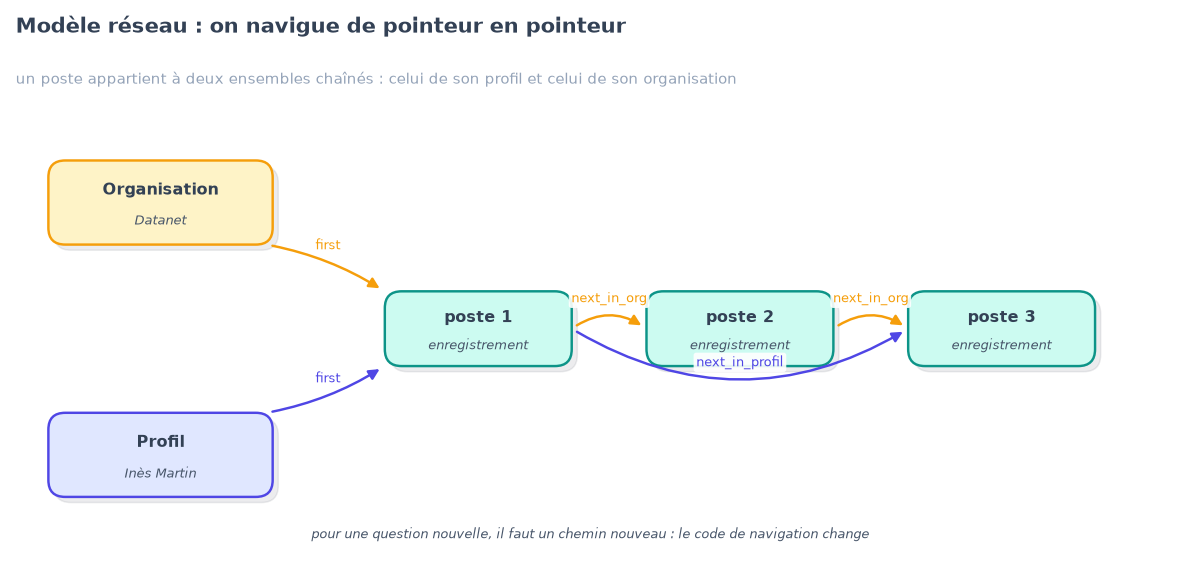

In [13]:
d = Diagram(12.5, 5.0, title="Modèle réseau : on navigue de pointeur en pointeur",
            subtitle="un poste appartient à deux ensembles chaînés : celui de son profil et celui de son organisation")
d.box("org", 1.6, 3.9, "Organisation", sub="Datanet", color=AMBER, w=2.4)
d.box("prof", 1.6, 1.2, "Profil", sub="Inès Martin", color=INDIGO, w=2.4)
for k, x in enumerate([5.0, 7.8, 10.6]):
    d.box(f"p{k}", x, 2.55, f"poste {k + 1}", sub="enregistrement", color=TEAL, w=2.0, h=0.8)
d.arrow("org", "p0", "first", color=AMBER, rad=-0.1)
d.arrow("p0", "p1", "next_in_org", color=AMBER, rad=-0.35)
d.arrow("p1", "p2", "next_in_org", color=AMBER, rad=-0.35)
d.arrow("prof", "p0", "first", color=INDIGO, rad=0.1)
d.arrow("p0", "p2", "next_in_profil", color=INDIGO, rad=0.3)
d.note(6.2, 0.35, "pour une question nouvelle, il faut un chemin nouveau : le code de navigation change", fontsize=8.5)
d.show()

Avec le chemin prévu, la navigation suit exactement autant de pointeurs que
l'organisation a de postes ; sans lui, elle visite **tous** les profils et tous leurs
postes, quelle que soit l'organisation. En relationnel, la même question s'écrit une fois
pour toutes en SQL ; créer l'index `positions_org` (section 3) a accéléré la requête sans
qu'on la réécrive. C'est l'argument décisif de Codd : l'**indépendance** entre la requête
et le chemin d'accès.

**Et les bases documents ?** Pour les données imbriquées (les listes du CV), elles
reviennent au modèle hiérarchique : les sous-éléments sont stockés **dans** le document
parent. Mais pour les relations plusieurs-à-un et plusieurs-à-plusieurs, elles font comme
le relationnel : l'élément lié est désigné par un identifiant unique, une **référence de
document** qui joue le rôle d'une clé étrangère, résolue à la lecture par une jointure ou
des requêtes successives. Elles n'ont donc pas repris le chemin de CODASYL.

> **À retenir.** Le modèle hiérarchique (IMS) ressemblait au modèle document et butait
> déjà sur les relations plusieurs-à-plusieurs. Le modèle réseau (CODASYL) les gérait
> par des chemins d'accès codés à la main ; le relationnel a gagné en confiant le choix
> des chemins à l'optimiseur. Les bases documents utilisent des références, comme le
> relationnel, pour ces relations.

## Synthèse

- **Normaliser** : l'information lisible en un seul exemplaire, référencée par un
  identifiant sans signification. Écritures en un point, lectures avec **jointure**.
- **Dénormaliser** : dupliquer pour lire sans jointure ; chaque mise à jour coûte autant
  que le nombre de copies, et une panne en cours de route laisse des copies incohérentes
  sans transaction atomique (chapitre 7).
- Les relations **plusieurs-à-un** et **plusieurs-à-plusieurs** appellent la
  normalisation : table d'association indexée dans les deux sens (chapitre
  3), ou références entre documents.
- Le modèle hiérarchique (IMS) butait déjà sur ces relations ; le modèle réseau (CODASYL) les gérait par des chemins d'accès codés à la main ; le relationnel a gagné grâce à l'optimiseur.

Le cours 3 aborde l'autre grand argument du débat : la **souplesse du schéma**, puis les
langages de requête pour documents. Quand les relations plusieurs-à-plusieurs dominent,
le modèle en **graphe** des cours 4 et 5 devient le plus naturel.